In [5]:
%%writefile final_decision.py
"""final_decision.py : décision finale Alert / No Alert."""
import os
import numpy as np
import pandas as pd
import joblib

CLASSES = ["falling", "lying", "not_lying"]
FEATURES = ["falling", "lying", "not_lying", "falling_max30", "lying_mean10",
            "falling_mean5", "falling_sum30", "lying_delta15",
            "fall_then_lie", "falling_speed", "lying_mean30"]
SEUIL = 0.6
N_CONSECUTIFS = 10
MODEL_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "rf_final.pkl")
_rf = None


def build_features(probs):
    """probs : (n_fenetres, 3) [falling, lying, not_lying], trié par temps."""
    df = pd.DataFrame(np.asarray(probs, dtype=float), columns=CLASSES)
    df["falling_max30"] = df["falling"].rolling(30, min_periods=1).max()
    df["lying_mean10"]  = df["lying"].rolling(10, min_periods=1).mean()
    df["falling_mean5"] = df["falling"].rolling(5, min_periods=1).mean()
    df["falling_sum30"] = df["falling"].rolling(30, min_periods=1).sum()
    l5 = df["lying"].rolling(5, min_periods=1).mean()
    df["lying_delta15"] = l5 - l5.shift(15).fillna(0)
    df["fall_then_lie"] = df["falling_max30"] * l5
    df["falling_speed"] = df["falling"].diff().fillna(0).rolling(10, min_periods=1).max()
    df["lying_mean30"]  = df["lying"].rolling(30, min_periods=1).mean()
    return df[FEATURES]


def alerte_video(proba, seuil=SEUIL, n=N_CONSECUTIFS):
    run = 0
    for p in proba:
        run = run + 1 if p > seuil else 0
        if run >= n:
            return True
    return False


def predict_final(cnn_preds, rnn_preds):
    global _rf
    rnn_preds = np.asarray(rnn_preds)
    if rnn_preds.ndim != 2 or rnn_preds.shape[0] == 0:
        return "No Alert"
    X = build_features(rnn_preds)
    if _rf is None and os.path.exists(MODEL_PATH):
        _rf = joblib.load(MODEL_PATH)
    if _rf is not None:
        proba = _rf.predict_proba(X)[:, 1]
    else:
        proba = np.maximum(X["falling"], X["lying"]).to_numpy()
    return "Alert" if alerte_video(proba) else "No Alert"


def niveau_alerte(proba, lying, seuil=SEUIL, n=N_CONSECUTIFS, m=30, lying_min=0.5):
    """'No Alert' / 'Proches' (alerte RF) / 'SAMU' (alerte + immobilité confirmée)."""
    run = 0
    for i, p in enumerate(proba):
        run = run + 1 if p > seuil else 0
        if run >= n:
            apres = np.asarray(lying)[i + 1:i + 1 + m]
            if len(apres) > 0 and apres.mean() > lying_min:
                return "SAMU"
            return "Proches"
    return "No Alert"


def predict_niveau(rnn_preds):
    global _rf

Overwriting final_decision.py


In [6]:
import final_decision
print(final_decision.SEUIL, len(final_decision.FEATURES))

0.6 11


In [7]:
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from final_decision import FEATURES, build_features, alerte_video, SEUIL, N_CONSECUTIFS

WINDOW = 10

In [8]:
print(os.listdir("."))

['embeddings.npz', 'embeddings_backup.npz', 'final_decision.py', 'frame_predictions.csv', 'frame_predictions_backup.csv', 'lstm_outputs.csv', 'models', 'Random_Forest_Fall_Detection.ipynb', 'rf_final.pkl', 'rnn_temporal_model.keras', '__pycache__']


In [9]:
data = np.load("embeddings.npz")
labels = pd.read_csv("frame_predictions.csv")

emb = pd.DataFrame({"sequence": data["sequence"].astype(str),
                    "frame": data["frame"],
                    "split": data["split"].astype(str),
                    "embedding": list(data["embeddings"])})
labels["sequence"] = labels["sequence"].astype(str)
labels["split"] = labels["split"].astype(str)

df = (emb.merge(labels[["sequence", "frame", "split", "true_class"]],
                on=["sequence", "frame", "split"])
         .sort_values(["sequence", "frame"]))
print(df.shape, df["split"].value_counts().to_dict())

(11544, 5) {'train': 7954, 'val': 1847, 'test': 1743}


In [10]:
from tensorflow.keras.models import load_model
lstm = load_model("rnn_temporal_model.keras")

rows = []
for (seq, sp), g in df.groupby(["sequence", "split"], sort=False):
    X = np.stack(g["embedding"].values).astype("float32")
    fr, y = g["frame"].to_numpy(), g["true_class"].to_numpy()
    idx = [i for i in range(len(g) - WINDOW + 1)
           if np.all(np.diff(fr[i:i + WINDOW]) == 1)]
    if not idx:
        continue
    P = lstm.predict(np.stack([X[i:i + WINDOW] for i in idx]), verbose=0)
    for i, p in zip(idx, P):
        rows.append([seq, sp, fr[i + WINDOW - 1], *p, y[i + WINDOW - 1]])

out = pd.DataFrame(rows, columns=["sequence", "split", "frame",
                                  "falling", "lying", "not_lying", "true_class"])
out.to_csv("lstm_outputs.csv", index=False)
out.head()

,sequence,split,frame,falling,lying,not_lying,true_class
0,adl-01,train,17,0.004423,0.000036,0.995541,not_lying
1,adl-01,train,18,0.009209,0.000047,0.990745,not_lying
2,adl-01,train,19,0.022465,0.000083,0.977452,not_lying
3,adl-01,train,20,0.043493,0.000119,0.956388,not_lying
4,adl-01,train,21,0.033165,0.000143,0.966692,not_lying


In [11]:
import importlib, final_decision
importlib.reload(final_decision)
from final_decision import FEATURES, build_features
print(FEATURES)  

['falling', 'lying', 'not_lying', 'falling_max30', 'lying_mean10', 'falling_mean5', 'falling_sum30', 'lying_delta15', 'fall_then_lie', 'falling_speed', 'lying_mean30']


In [12]:
out = out.sort_values(["sequence", "frame"]).reset_index(drop=True)

parts = []
for seq, g in out.groupby("sequence", sort=False):
    f = build_features(g[["falling", "lying", "not_lying"]].to_numpy())
    f.index = g.index
    parts.append(f)
out[FEATURES] = pd.concat(parts)

# danger = falling ou lying dans une vidéo de chute
out["target"] = (out["sequence"].str.startswith("fall")
                 & (out["true_class"] != "not_lying")).astype(int)

train, val, test = (out[out.split == s].copy() for s in ["train", "val", "test"])
print(len(train), len(test), train["target"].mean().round(3))

7503 1648 0.183


In [13]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=10, max_depth=6, random_state=42)
rf.fit(train[FEATURES], train["target"])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 

In [14]:
val["proba"] = rf.predict_proba(val[FEATURES])[:, 1]
rows = []
for s in [0.5, 0.7, 0.8, 0.9]:
    for N in [5, 10, 15]:
        a = [(q.startswith("fall"), alerte_video(g["proba"].to_numpy(), seuil=s, n=N))
             for q, g in val.groupby("sequence")]
        rows.append([s, N,
                     sum(v and al for v, al in a),
                     sum(v and not al for v, al in a),
                     sum((not v) and al for v, al in a)])
pd.DataFrame(rows, columns=["seuil", "N", "détectées", "ratées", "fausses"])

,seuil,N,détectées,ratées,fausses
0,0.5,5,4,0,6
1,0.5,10,4,0,5
2,0.5,15,4,0,4
3,0.7,5,4,0,3
4,0.7,10,4,0,3
5,0.7,15,4,0,3
6,0.8,5,4,0,2
7,0.8,10,4,0,2
8,0.8,15,4,0,1
9,0.9,5,3,1,1


In [15]:
from sklearn.model_selection import GroupKFold

dev = pd.concat([train, val]).reset_index(drop=True)
grid = [(s, n) for s in [0.6, 0.7, 0.8, 0.9] for n in [5, 10, 15]]
tot = {g: [0, 0, 0] for g in grid}

for tr_i, va_i in GroupKFold(n_splits=5).split(dev, dev["target"], groups=dev["sequence"]):
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                               min_samples_leaf=10, max_depth=6, random_state=42)
    m.fit(dev.loc[tr_i, FEATURES], dev.loc[tr_i, "target"])
    fold = dev.loc[va_i].copy()
    fold["proba"] = m.predict_proba(fold[FEATURES])[:, 1]
    for q, g in fold.groupby("sequence"):
        v = q.startswith("fall")
        p = g["proba"].to_numpy()
        for (s, n) in grid:
            a = alerte_video(p, seuil=s, n=n)
            tot[(s, n)][0] += v and a
            tot[(s, n)][1] += v and not a
            tot[(s, n)][2] += (not v) and a

pd.DataFrame(tot, index=["détectées", "ratées", "fausses"]).T

détectées  ratées  fausses
0.6 5          26       0       19
    10         26       0       14
    15         24       2       13
0.7 5          25       1       14
    10         25       1       13
    15         23       3       13
0.8 5          23       3       12
    10         22       4       10
    15         20       6        8
0.9 5          16      10        6
    10         14      12        4
    15          9      17        2

In [16]:
rows = []
for s in [0.6, 0.7, 0.8]:
    for N in [5, 10, 15]:
        a = [(q.startswith("fall"),
              alerte_video(np.maximum(g["falling"], g["lying"]).to_numpy(), seuil=s, n=N))
             for q, g in dev.groupby("sequence")]
        rows.append([s, N, sum(v and al for v, al in a),
                     sum(v and not al for v, al in a),
                     sum((not v) and al for v, al in a)])
pd.DataFrame(rows, columns=["seuil", "N", "détectées", "ratées", "fausses"])

,seuil,N,détectées,ratées,fausses
0,0.6,5,26,0,17
1,0.6,10,26,0,15
2,0.6,15,25,1,14
3,0.7,5,26,0,15
4,0.7,10,25,1,15
5,0.7,15,25,1,13
6,0.8,5,26,0,15
7,0.8,10,25,1,13
8,0.8,15,25,1,12


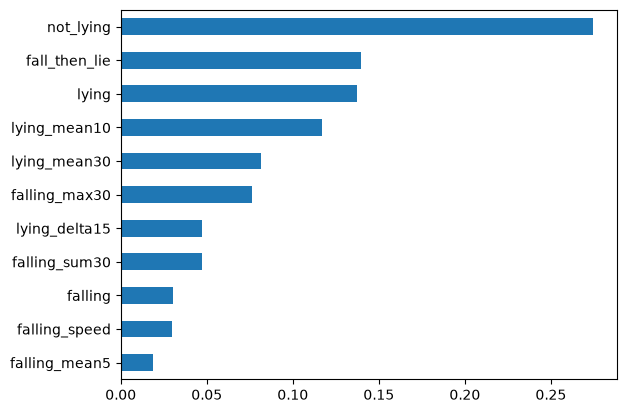

In [17]:
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh()
plt.show()

In [18]:
joblib.dump(rf, "rf_final.pkl")

['rf_final.pkl']

In [19]:
oof = []
for tr_i, va_i in GroupKFold(n_splits=5).split(dev, dev["target"], groups=dev["sequence"]):
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                               min_samples_leaf=10, max_depth=6, random_state=42)
    m.fit(dev.loc[tr_i, FEATURES], dev.loc[tr_i, "target"])
    f = dev.loc[va_i].copy()
    f["proba"] = m.predict_proba(f[FEATURES])[:, 1]
    oof.append(f)
oof = pd.concat(oof)

fp = [q for q, g in oof.groupby("sequence")
      if not q.startswith("fall") and alerte_video(g["proba"].to_numpy(), seuil=0.6, n=10)]
print(len(fp), fp)

14 ['adl-10', 'adl-19', 'adl-21', 'adl-22', 'adl-27', 'adl-32', 'adl-33', 'adl-34', 'adl-35', 'adl-36', 'adl-37', 'adl-38', 'adl-39', 'adl-40']


In [20]:
diag = (oof.assign(lying_true=(oof.true_class == "lying"),
                   falling_true=(oof.true_class == "falling"))
           .groupby("sequence")
           .agg(max_falling=("falling", "max"), mean_lying=("lying", "mean"),
                frac_lying_true=("lying_true", "mean"),
                frac_falling_true=("falling_true", "mean")))
diag = diag[~diag.index.str.startswith("fall")]
diag["FP"] = diag.index.isin(fp)

print(diag.groupby("FP").mean().round(2))
print(diag[diag.FP].round(2))

       max_falling  mean_lying  frac_lying_true  frac_falling_true
FP                                                                
False         0.55         0.0             0.00               0.00
True          0.98         0.3             0.29               0.19
          max_falling  mean_lying  frac_lying_true  frac_falling_true    FP
sequence                                                                   
adl-10           0.96        0.28             0.35               0.10  True
adl-19           0.94        0.07             0.00               0.00  True
adl-21           0.99        0.24             0.24               0.23  True
adl-22           0.91        0.34             0.31               0.08  True
adl-27           0.97        0.08             0.00               0.00  True
adl-32           1.00        0.45             0.41               0.25  True
adl-33           1.00        0.36             0.34               0.35  True
adl-34           1.00        0.36             0.

In [21]:
fn = [q for q, g in oof.groupby("sequence")
      if q.startswith("fall") and not alerte_video(g["proba"].to_numpy(), seuil=0.6, n=10)]
print(fn)
print(oof[oof.sequence.isin(fn)].groupby("sequence")
         .agg(max_proba=("proba", "max"), max_falling=("falling", "max"),
              n_frames=("frame", "count")).round(2))

[]
Empty DataFrame
Columns: [max_proba, max_falling, n_frames]
Index: []


In [22]:
rf.fit(dev[FEATURES], dev["target"])
test = test.copy()
test["proba"] = rf.predict_proba(test[FEATURES])[:, 1]
res = pd.DataFrame([[s, s.startswith("fall"), alerte_video(g["proba"].to_numpy(), seuil=0.6, n=10)]
                    for s, g in test.groupby("sequence")],
                   columns=["sequence", "vraie_chute", "alerte"])
print(pd.crosstab(res["vraie_chute"], res["alerte"],
                  rownames=["chute réelle"], colnames=["alerte"]))
joblib.dump(rf, "rf_final.pkl")

alerte        False  True 
chute réelle              
False             1      5
True              0      4


['rf_final.pkl']

In [23]:
import importlib, final_decision
importlib.reload(final_decision)
from final_decision import niveau_alerte

rows = [[q, q.startswith("fall"),
         niveau_alerte(g["proba"].to_numpy(), g["lying"].to_numpy(), seuil=0.6, n=10)]
        for q, g in oof.groupby("sequence")]
r = pd.DataFrame(rows, columns=["sequence", "vraie_chute", "niveau"])
print(pd.crosstab(r["vraie_chute"], r["niveau"]))

niveau       No Alert  Proches  SAMU
vraie_chute                         
False              20        9     5
True                0        7    19


In [24]:
base = [[q, q.startswith("fall"),
         niveau_alerte(np.maximum(g["falling"], g["lying"]).to_numpy(),
                       g["lying"].to_numpy(), seuil=0.6, n=10)]
        for q, g in oof.groupby("sequence")]
rb = pd.DataFrame(base, columns=["sequence", "vraie_chute", "niveau"])
print(pd.crosstab(rb["vraie_chute"], rb["niveau"]))

niveau       No Alert  Proches  SAMU
vraie_chute                         
False              19       12     3
True                0        9    17


In [25]:
import importlib, os, final_decision
importlib.reload(final_decision)
from final_decision import predict_final

for q in [test[test.sequence.str.startswith("fall")].sequence.iloc[0],
          test[test.sequence.str.startswith("adl")].sequence.iloc[0]]:
    P = test[test.sequence == q][["falling", "lying", "not_lying"]].to_numpy()
    print(q, predict_final(None, P), "| RF chargé:", final_decision._rf is not None)

print(predict_final(None, np.empty((0, 3))))   # cas vide → No Alert

fall-16 Alert | RF chargé: True
adl-05 Alert | RF chargé: True
No Alert


In [ ]:
import joblib

joblib.dump(rf, "rf_final.joblib")

print("Model saved successfully!")

Model saved successfully!


In [27]:
import joblib

rf_loaded = joblib.load("rf_final.joblib")

print(type(rf_loaded))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
